# EDA: популярность айтемов внутри сессий (после build_sessions)

Сначала строим сессии через `build_sessions` (`src/data_preprocessing/session.py`),
а затем считаем частотуアイтемов **уже внутри сессий** — так мы видим реальную
популярность в контексте сессий, а не в сырых логах с однократными кликами.

Источники:
- Park & Tuzhilin, *The Long Tail of Recommender Systems*, RecSys'08 — делят айтемы на head / tail.
- `compute_strata` в `src/models/sasrec/metrics/coverage.py` — текущая стратификация equal thirds.


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

sns.set_style("whitegrid")
sns.set_palette("viridis")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

RAW = Path("../../data/raw/yambda_50m_listens.parquet")
OUT = Path("../../reports/figures")
OUT.mkdir(parents=True, exist_ok=True)


## 1. Загрузка сырых данных


In [2]:
df = pl.read_parquet(RAW)
print(f"всего строк: {df.height:,}")
print(f"колонки: {df.columns}")
print(f"диапазон timestamp: {df['timestamp'].min()} .. {df['timestamp'].max()}")


всего строк: 46,467,212
колонки: ['uid', 'timestamp', 'item_id', 'is_organic', 'played_ratio_pct', 'track_length_seconds']
диапазон timestamp: 0 .. 26000000


## 2. Построение сессий через build_sessions

Вызываем `build_sessions` с конфигом по умолчанию:
- `played_ratio_pct >= 50` (фильтр однократных кликов)
- правого хвоста логнормального распределения gap (порог `exp(mean + 2*std)`)
- `min_session_len = 10` (короткие сессии отбрасываются)
- удаление временных выбросов (боксплот 1.5×IQR)


In [3]:
from data_preprocessing.session import BuildSessionsConfig, build_sessions

cfg = BuildSessionsConfig()
sessions = build_sessions(df, config=cfg)
print(f"строк после build_sessions: {sessions.height:,}")
print(f"уникальных сессий: {sessions.group_by(['uid', 'session_id']).len().height:,}")
print(f"уникальных айтемов в сессиях: {sessions['item_id'].n_unique():,}")
print(f"колонки: {sessions.columns}")


строк после build_sessions: 20,880,086
уникальных сессий: 776,805
уникальных айтемов в сессиях: 544,854
колонки: ['uid', 'timestamp', 'item_id', 'is_organic', 'played_ratio_pct', 'track_length_seconds', 'session_id']


## 3. Базовая статистика сессий

Средняя длина сессии, медиана, максимум — чтобы понимать, что попадает в датасет.


In [4]:
session_lens = (
    sessions.group_by(["uid", "session_id"])
    .agg(pl.len().alias("len"))
    .sort("len", descending=True)
)
print(session_lens.describe())
print(f"сессий длиной 1: {(session_lens['len'] == 1).sum():,}")
print(f"сессий длиной > 50: {(session_lens['len'] > 50).sum():,}")
print(f"медиана длины: {session_lens['len'].median()}")


shape: (9, 4)
┌────────────┬───────────────┬────────────┬───────────┐
│ statistic  ┆ uid           ┆ session_id ┆ len       │
│ ---        ┆ ---           ┆ ---        ┆ ---       │
│ str        ┆ f64           ┆ f64        ┆ f64       │
╞════════════╪═══════════════╪════════════╪═══════════╡
│ count      ┆ 776805.0      ┆ 776805.0   ┆ 776805.0  │
│ null_count ┆ 0.0           ┆ 0.0        ┆ 0.0       │
│ mean       ┆ 498337.027826 ┆ 190.060042 ┆ 26.879443 │
│ std        ┆ 285721.890862 ┆ 171.65841  ┆ 26.386061 │
│ min        ┆ 100.0         ┆ 1.0        ┆ 10.0      │
│ 25%        ┆ 254700.0      ┆ 59.0       ┆ 14.0      │
│ 50%        ┆ 490500.0      ┆ 141.0      ┆ 20.0      │
│ 75%        ┆ 742900.0      ┆ 274.0      ┆ 32.0      │
│ max        ┆ 1e6           ┆ 1306.0     ┆ 13533.0   │
└────────────┴───────────────┴────────────┴───────────┘
сессий длиной 1: 0
сессий длиной > 50: 83,191
медиана длины: 20.0


## 4. Частота айтемов внутри сессий

Считаем, сколько раз каждый айтем встречается в сессиях (число вхождений, а не число сессий,
где есть айтем — для сравнения с сырыми логами).


In [6]:
item_freq = (
    sessions.group_by("item_id")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
)
print(item_freq.describe())
print("Топ-20 айтемов в сессиях:")
print(item_freq.head(20))


shape: (9, 3)
┌────────────┬────────────┬────────────┐
│ statistic  ┆ item_id    ┆ count      │
│ ---        ┆ ---        ┆ ---        │
│ str        ┆ f64        ┆ f64        │
╞════════════╪════════════╪════════════╡
│ count      ┆ 544854.0   ┆ 544854.0   │
│ null_count ┆ 0.0        ┆ 0.0        │
│ mean       ┆ 4.6902e6   ┆ 38.322351  │
│ std        ┆ 2.7107e6   ┆ 215.732767 │
│ min        ┆ 26.0       ┆ 1.0        │
│ 25%        ┆ 2.341065e6 ┆ 1.0        │
│ 50%        ┆ 4.690589e6 ┆ 3.0        │
│ 75%        ┆ 7.040372e6 ┆ 13.0       │
│ max        ┆ 9.390601e6 ┆ 18795.0    │
└────────────┴────────────┴────────────┘
Топ-20 айтемов в сессиях:
shape: (20, 2)
┌─────────┬───────┐
│ item_id ┆ count │
│ ---     ┆ ---   │
│ u32     ┆ u32   │
╞═════════╪═══════╡
│ 5862961 ┆ 18795 │
│ 6901374 ┆ 18625 │
│ 5635052 ┆ 17373 │
│ 9378983 ┆ 17228 │
│ 3542184 ┆ 17202 │
│ …       ┆ …     │
│ 6155741 ┆ 10611 │
│ 8743390 ┆ 10551 │
│ 6853370 ┆ 10387 │
│ 5734320 ┆ 10302 │
│ 1464852 ┆ 10284 │
└─────────

## 5. Распределение частоты (гистограмма + Zipf)

То же самое, что и раньше, но уже на сессионных данных.


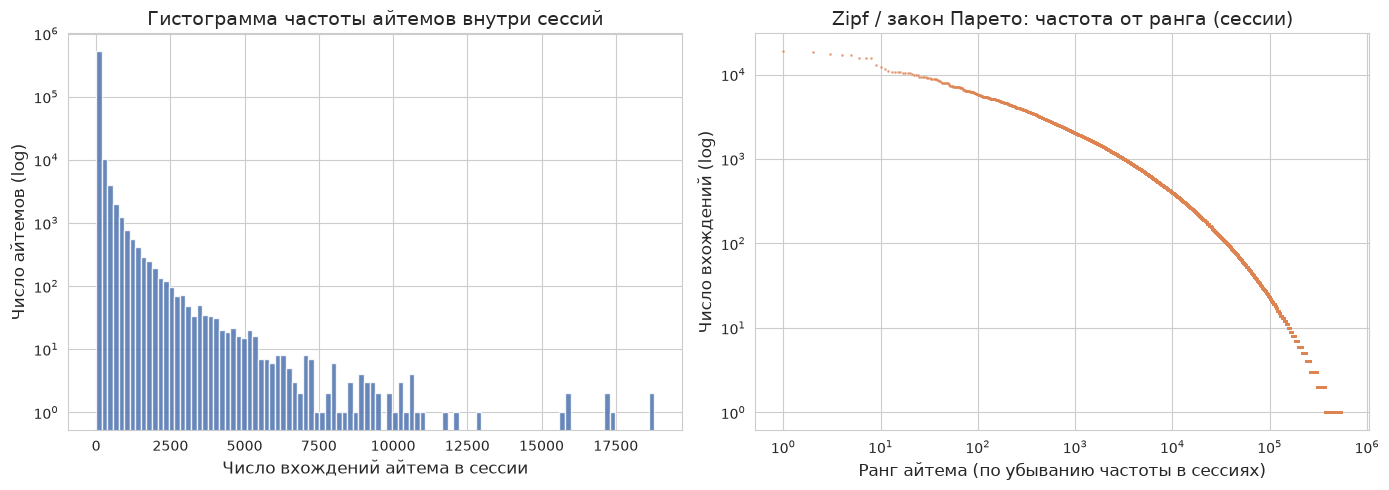

In [7]:
counts = item_freq["count"].to_numpy()
n_items = len(counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(counts, bins=100, color="#4c72b0", edgecolor="white", alpha=0.85)
axes[0].set_yscale("log")
axes[0].set_xlabel("Число вхождений айтема в сессии")
axes[0].set_ylabel("Число айтемов (log)")
axes[0].set_title("Гистограмма частоты айтемов внутри сессий")

sorted_counts = np.sort(counts)[::-1]
ranks = np.arange(1, n_items + 1)
axes[1].loglog(ranks, sorted_counts, ".", markersize=2, color="#dd8452", alpha=0.6)
axes[1].set_xlabel("Ранг айтема (по убыванию частоты в сессиях)")
axes[1].set_ylabel("Число вхождений (log)")
axes[1].set_title("Zipf / закон Парето: частота от ранга (сессии)")

plt.tight_layout()
plt.savefig(OUT / "session_item_frequency.png", dpi=150)
plt.show()


## 6. Кривая Лоренца (сессии)

Кривая Лоренца показывает неравенство: отсортируем айтемы по возрастанию частоты и
посмотрим, какую долю всех вхождений дают самые редкие N% айтемов.


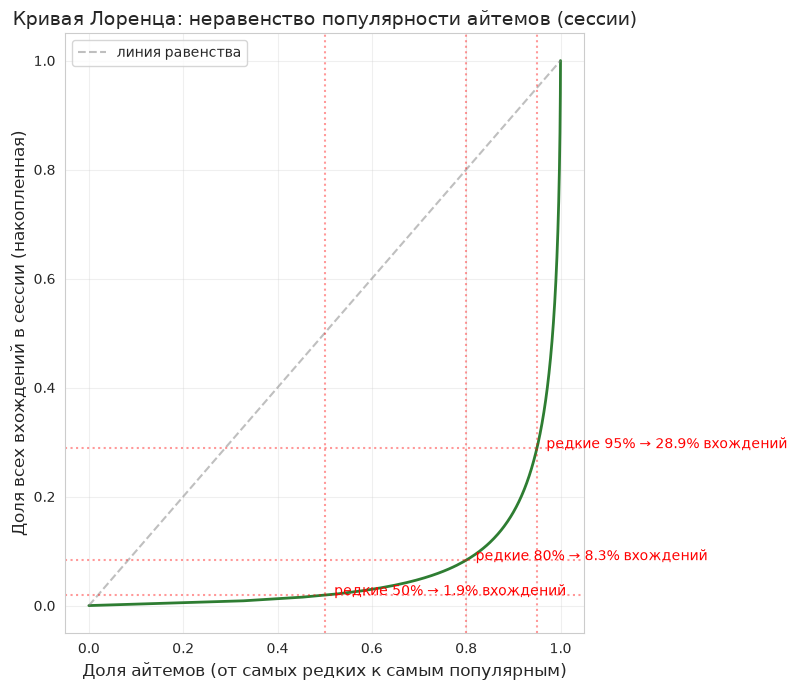

In [8]:
sorted_counts_asc = np.sort(counts)
cumulative_share = np.cumsum(sorted_counts_asc) / sorted_counts_asc.sum()
item_share = np.arange(1, n_items + 1) / n_items

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(item_share, cumulative_share, color="#2e7d32", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", alpha=0.5, label="линия равенства")
ax.set_xlabel("Доля айтемов (от самых редких к самым популярным)")
ax.set_ylabel("Доля всех вхождений в сессии (накопленная)")
ax.set_title("Кривая Лоренца: неравенство популярности айтемов (сессии)")
ax.legend()
ax.grid(True, alpha=0.3)

for pct in (0.5, 0.8, 0.95):
    idx = int(pct * n_items)
    share = cumulative_share[idx - 1] if idx > 0 else 0
    ax.axvline(pct, color="red", linestyle=":", alpha=0.4)
    ax.axhline(share, color="red", linestyle=":", alpha=0.4)
    ax.text(
        pct + 0.02,
        share,
        f"редкие {pct:.0%} → {share:.1%} вхождений",
        fontsize=10,
        color="red",
    )

plt.tight_layout()
plt.savefig(OUT / "session_lorenz_curve.png", dpi=150)
plt.show()


## 7. Gini-коэффициент

Измерим неравенство: 0 = все айтемы равны, 1 = один айтем забирает всё.


In [9]:
def gini(x: np.ndarray) -> float:
    x = np.sort(x)
    nn = len(x)
    index = np.arange(1, nn + 1)
    return float((2 * np.sum(index * x) / (nn * np.sum(x))) - (nn + 1) / nn)

g = gini(counts)
print(f"Gini-коэффициент (сессии): {g:.3f}")
print("0.3 — умеренное неравенство, 0.5+ — сильное, >0.7 — очень сильное")


Gini-коэффициент (сессии): 0.875
0.3 — умеренное неравенство, 0.5+ — сильное, >0.7 — очень сильное


## 8. Сравнение стратификаций

Сравним три способа разбить айтемы на группы:

1. **Равные thirds** (текущий в `compute_strata`): 33% / 33% / 33% по количеству айтемов.
2. **Частотные корзины**: 1 вхождение, 2–5, 6–20, 21+.
3. **Pareto (80/20)**: голова = минимальный набор топ-аитемов, дающих 80% всех вхождений, хвост = всё остальное.


In [10]:
from dataclasses import dataclass


@dataclass
class Stratum:
    name: str
    n_items: int
    n_interactions: int
    share_items: float
    share_interactions: float


strata_report = []
third = n_items // 3
for i, name in enumerate(["head", "mid", "tail"]):
    sl = slice(i * third, (i + 1) * third if i < 2 else n_items)
    sub = item_freq[sl]
    strata_report.append(
        Stratum(
            name=f"equal_thirds_{name}",
            n_items=int(sub.height),
            n_interactions=int(sub["count"].sum()),
            share_items=sub.height / n_items,
            share_interactions=sub["count"].sum() / sessions.height,
        )
    )

buckets = [
    (1, 1, "bucket_1"),
    (2, 5, "bucket_2_5"),
    (6, 20, "bucket_6_20"),
    (21, int(1e9), "bucket_21_plus"),
]
for lo, hi, name in buckets:
    sub = item_freq.filter(
        (pl.col("count") >= lo) & (pl.col("count") <= hi)
    )
    strata_report.append(
        Stratum(
            name=name,
            n_items=int(sub.height),
            n_interactions=int(sub["count"].sum()),
            share_items=sub.height / n_items,
            share_interactions=sub["count"].sum() / sessions.height,
        )
    )

sorted_desc = item_freq.sort("count", descending=True)
cum = np.cumsum(sorted_desc["count"].to_numpy()) / sessions.height
cut = int(np.searchsorted(cum, 0.80)) + 1
for name, sub in (
    ("pareto_head", sorted_desc.head(cut)),
    ("pareto_tail", sorted_desc.slice(cut)),
):
    strata_report.append(
        Stratum(
            name=name,
            n_items=int(sub.height),
            n_interactions=int(sub["count"].sum()),
            share_items=sub.height / n_items,
            share_interactions=sub["count"].sum() / sessions.height,
        )
    )

report = pl.DataFrame(
    {
        "strategy": [s.name for s in strata_report],
        "n_items": [s.n_items for s in strata_report],
        "share_items": [round(s.share_items, 4) for s in strata_report],
        "share_interactions": [
            round(s.share_interactions, 4) for s in strata_report
        ],
    }
)
print(report)
report.write_csv(OUT / "session_strata_comparison.csv")


shape: (9, 4)
┌───────────────────┬─────────┬─────────────┬────────────────────┐
│ strategy          ┆ n_items ┆ share_items ┆ share_interactions │
│ ---               ┆ ---     ┆ ---         ┆ ---                │
│ str               ┆ i64     ┆ f64         ┆ f64                │
╞═══════════════════╪═════════╪═════════════╪════════════════════╡
│ equal_thirds_head ┆ 181618  ┆ 0.3333      ┆ 0.9593             │
│ equal_thirds_mid  ┆ 181618  ┆ 0.3333      ┆ 0.0317             │
│ equal_thirds_tail ┆ 181618  ┆ 0.3333      ┆ 0.009              │
│ bucket_1          ┆ 174438  ┆ 0.3202      ┆ 0.0084             │
│ bucket_2_5        ┆ 158068  ┆ 0.2901      ┆ 0.0228             │
│ bucket_6_20       ┆ 106635  ┆ 0.1957      ┆ 0.0553             │
│ bucket_21_plus    ┆ 105713  ┆ 0.194       ┆ 0.9136             │
│ pareto_head       ┆ 45375   ┆ 0.0833      ┆ 0.8                │
│ pareto_tail       ┆ 499479  ┆ 0.9167      ┆ 0.2                │
└───────────────────┴─────────┴─────────────┴───

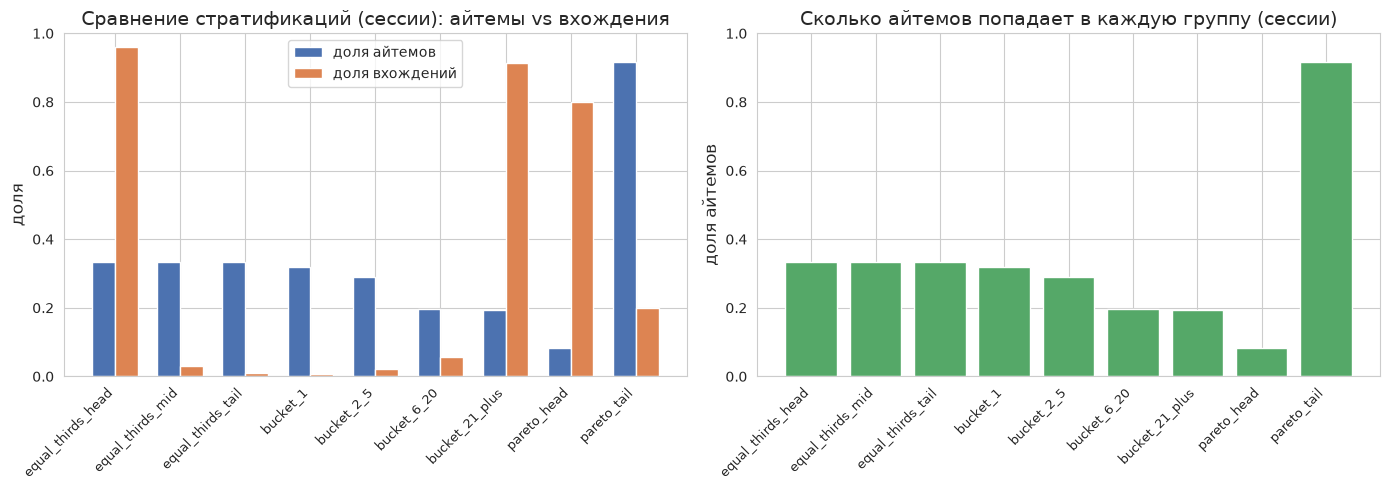

In [11]:
strategies = report["strategy"].to_list()
items_share = report["share_items"].to_numpy()
inter_share = report["share_interactions"].to_numpy()
x = np.arange(len(strategies))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(x - width / 2, items_share, width, label="доля айтемов", color="#4c72b0")
axes[0].bar(
    x + width / 2, inter_share, width, label="доля вхождений", color="#dd8452"
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(strategies, rotation=45, ha="right", fontsize=9)
axes[0].set_ylabel("доля")
axes[0].set_title("Сравнение стратификаций (сессии): айтемы vs вхождения")
axes[0].legend()
axes[0].set_ylim(0, 1)

axes[1].bar(range(len(strategies)), items_share, color="#55a868")
axes[1].set_xticks(range(len(strategies)))
axes[1].set_xticklabels(strategies, rotation=45, ha="right", fontsize=9)
axes[1].set_ylabel("доля айтемов")
axes[1].set_title("Сколько айтемов попадает в каждую группу (сессии)")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(OUT / "session_strata_comparison.png", dpi=150)
plt.show()


## 9. Выводы

- Если Gini высокий (>0.7), равные thirds бессмысленны: «голова» равного деления забирает
  большинство вхождений, а «хвост» — ничтожную долю.
- logQ коррекция борется с этим эффектом (популярность смещает рекомендации к голове),
  но без температуры и нормализации эмбеддингов хвост не вытягивается.
- Рекомендация: заменить `compute_strata` с равными thirds на Pareto-разделение
  или частотные корзины.
